In [1]:
"""
import nltk
nltk.download()
"""

'\nimport nltk\nnltk.download()\n'

In [2]:
"""
import nltk

nltk.download('punkt_tab')  # 문장·단어 토큰화용
nltk.download('stopwords')  # 불용어 목록
"""

"\nimport nltk\n\nnltk.download('punkt_tab')  # 문장·단어 토큰화용\nnltk.download('stopwords')  # 불용어 목록\n"

In [3]:
import pandas as pd
import re
from functools import reduce

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import STOPWORDS, WordCloud

In [4]:
url = 'https://raw.githubusercontent.com/prof-dana/Lecture-Code/refs/heads/main/AdvancedMachineLearning/data/riss_bigdata.csv'

data = pd.read_csv(url)
data.head()

,Unnamed: 0,번호,제목,저자,출판사,출판일
0,NaN,1,Call for Special Issue Papers: Soft Computing ...,"Chilamkurti, Naveen; Paul, Anand; Kumar, Akshi",Mary Ann Leibert,2020
1,NaN,2,"Big Data, Efficient Markets, and the End of Da...","Urbaczewski, Andrew; Elmore, Ryan",Mary Ann Leibert,2018
2,NaN,3,Big Data and Predictive Analytics in Health Care,unknown,Mary Ann Leibert,2014
3,NaN,4,Call for Special Issue Papers: Internet of Med...,"Din, Sadia; Aslan, Nauman; Cheung, Simon K.S.;...",Mary Ann Leibert,2020
4,NaN,5,Big Data Literature Search,unknown,Mary Ann Leibert,2014


In [5]:
all_title = data['제목']
all_title #출력하여 내용 확인

0      Call for Special Issue Papers: Soft Computing ...
1      Big Data, Efficient Markets, and the End of Da...
2       Big Data and Predictive Analytics in Health Care
3      Call for Special Issue Papers: Internet of Med...
4                             Big Data Literature Search
                             ...                        
995    Big data analysis of swimming pools' impact on...
996    MonkeyKing: Adaptive Parameter Tuning on Big D...
997    Curating Big Data Made Simple: Perspectives fr...
998                 Big Data 2.0: Cataclysm or Catalyst?
999    Does Medical School Training Relate to Practic...
Name: 제목, Length: 1000, dtype: object

In [6]:
stopWords = set(stopwords.words("english"))
lemma = WordNetLemmatizer()

words = []#표제어 추출
for title in all_title:
    EnWords = re.sub(r"[^a-zA-Z]+", " ", str(title))
    EnWordsToken = word_tokenize(EnWords.lower())
    EnWordsTokenStop = [ w for w in EnWordsToken if w not in stopWords]
    EnWordsTokenStopLemma = [ lemma.lemmatize(w) for w in EnWordsTokenStop]
    words.append(EnWordsTokenStopLemma)

print(words)

[['call', 'special', 'issue', 'paper', 'soft', 'computing', 'model', 'big', 'data', 'internet', 'thing'], ['big', 'data', 'efficient', 'market', 'end', 'daily', 'fantasy', 'sport', 'know'], ['big', 'data', 'predictive', 'analytics', 'health', 'care'], ['call', 'special', 'issue', 'paper', 'internet', 'medical', 'thing', 'big', 'data', 'pervasive', 'medical', 'care'], ['big', 'data', 'literature', 'search'], ['big', 'data', 'ensemble', 'clinical', 'prediction', 'healthcare', 'data', 'using', 'deep', 'learning', 'model'], ['call', 'special', 'issue', 'paper', 'cloud', 'computing', 'big', 'data', 'cognitive', 'iot'], ['call', 'special', 'issue', 'paper', 'big', 'data', 'analytics', 'industrial', 'intelligence'], ['u', 'army', 'person', 'event', 'data', 'environment', 'military', 'civilian', 'big', 'data', 'enterprise'], ['exploiting', 'reused', 'based', 'sharing', 'work', 'opportunity', 'big', 'data', 'multiquery', 'optimization', 'flink'], ['big', 'data', 'machine', 'analyze', 'stock', '

In [7]:
words2 = list(reduce(lambda x, y: x+y, words))
print(words2[:5]) #출력하여 내용 확인

['call', 'special', 'issue', 'paper', 'soft']


In [8]:
count = Counter(words2)
count #출력하여 내용 확인

Counter({'data': 1239,
         'big': 1112,
         'analytics': 113,
         'based': 102,
         'analysis': 97,
         'driven': 71,
         'system': 62,
         'using': 56,
         'approach': 56,
         'issue': 48,
         'learning': 48,
         'model': 46,
         'challenge': 44,
         'application': 40,
         'new': 39,
         'special': 37,
         'management': 36,
         'framework': 36,
         'algorithm': 36,
         'call': 34,
         'research': 34,
         'science': 34,
         'platform': 34,
         'paper': 32,
         'health': 31,
         'cloud': 30,
         'era': 30,
         'opportunity': 28,
         'network': 27,
         'machine': 26,
         'mining': 26,
         'processing': 26,
         'technology': 26,
         'computing': 25,
         'performance': 25,
         'method': 25,
         'earth': 25,
         'optimization': 24,
         'perspective': 24,
         'business': 24,
         'smart': 24,
   

In [9]:
word_count = dict()

for tag, counts in count.most_common(50):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

data : 1239
big : 1112
analytics : 113
based : 102
analysis : 97
driven : 71
system : 62
using : 56
approach : 56
issue : 48
learning : 48
model : 46
challenge : 44
application : 40
new : 39
special : 37
management : 36
framework : 36
algorithm : 36
call : 34
research : 34
science : 34
platform : 34
paper : 32
health : 31
cloud : 30
era : 30
opportunity : 28
network : 27
machine : 26
mining : 26
processing : 26
technology : 26
computing : 25
performance : 25
method : 25
earth : 25
optimization : 24
perspective : 24
business : 24
smart : 24
distributed : 23
information : 23
use : 23
review : 22
process : 22
world : 22
intelligence : 21
service : 21
development : 20


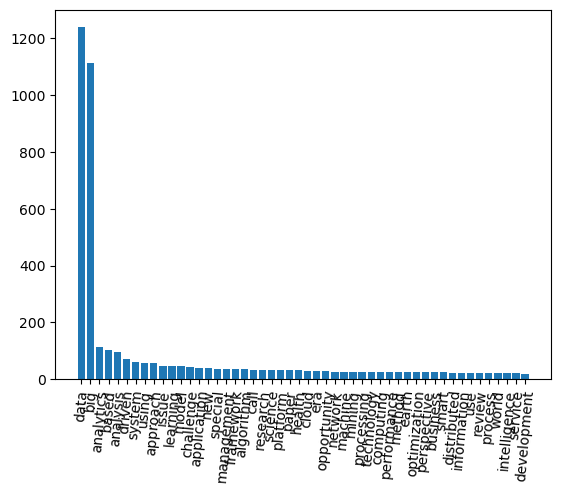

In [10]:
sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)#단어
sorted_Values = sorted(word_count.values(), reverse = True)#카운팅값

plt.bar(range(len(word_count)), sorted_Values, align = 'center')

plt.xticks( range(len(word_count)), list(sorted_Keys), rotation = 85)
plt.show()

In [11]:
summary_year = data.groupby('출판일', as_index = False)['번호'].count()
summary_year #출력하여 내용 확인

,출판일,번호
0,2003,1
1,2004,1
2,2011,5
3,2012,19
4,2013,50
5,2014,124
6,2015,92
7,2016,112
8,2017,129
9,2018,118


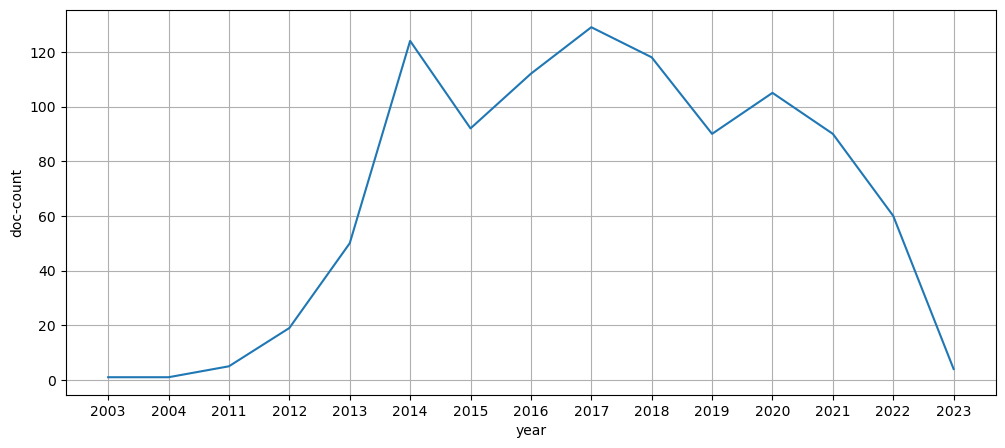

In [12]:
plt.figure(figsize = (12, 5))
plt.plot(range(len(summary_year)), summary_year['번호'])

plt.xticks( range(len(summary_year)), [text for text in summary_year['출판일']])
plt.xlabel("year")
plt.ylabel("doc-count")
plt.grid(True)

plt.show()

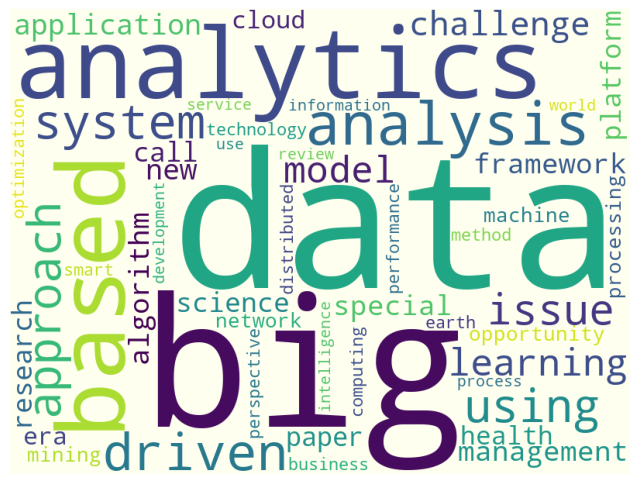

In [13]:
stopwords = set(STOPWORDS)
wc = WordCloud(background_color = 'ivory', stopwords = stopwords,width = 800, height = 600)
cloud = wc.generate_from_frequencies(word_count)

plt.figure(figsize = (8,8))
plt.imshow(cloud)
plt.axis('off')
plt.show()

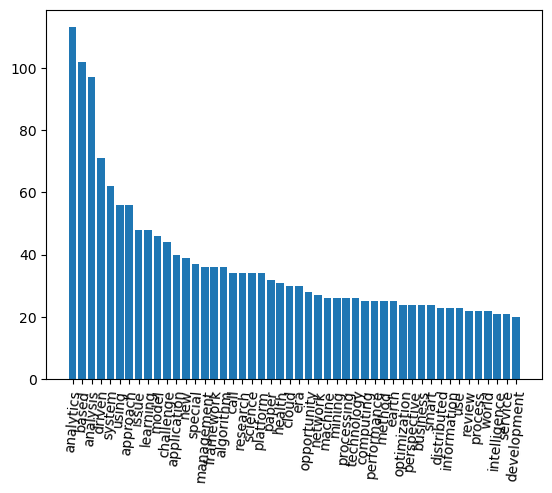

In [14]:
# 검색어로 사용한 'big'과 'data' 항목 제거 하기
del word_count['big']
del word_count['data']

sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)#단어
sorted_Values = sorted(word_count.values(), reverse = True)#카운팅값

plt.bar(range(len(word_count)), sorted_Values, align = 'center')

plt.xticks( range(len(word_count)), list(sorted_Keys), rotation = 85)
plt.show()

In [15]:
from konlpy.tag import Okt

nlp = Okt()
print(nlp.nouns("한국어 단어 빈도를 분석합니다."))

['한국어', '단어', '빈도', '분석']


In [16]:
import pandas as pd
from konlpy.tag import Okt
from collections import Counter

url = "https://raw.githubusercontent.com/songys/Chatbot_data/master/ChatbotData.csv"
data = pd.read_csv(url)
data.head()

,Q,A,label
0,12시 땡!,하루가 또 가네요.,0
1,1지망 학교 떨어졌어,위로해 드립니다.,0
2,3박4일 놀러가고 싶다,여행은 언제나 좋죠.,0
3,3박4일 정도 놀러가고 싶다,여행은 언제나 좋죠.,0
4,PPL 심하네,눈살이 찌푸려지죠.,0


In [17]:
#사랑 라벨의 질문 데이터 준비
d = data[data['label']==0]['Q']
d = d.dropna()
d.head()

0             12시 땡!
1        1지망 학교 떨어졌어
2       3박4일 놀러가고 싶다
3    3박4일 정도 놀러가고 싶다
4            PPL 심하네
Name: Q, dtype: object

In [18]:
#공백으로 연결해 하나의 문자열 text로 저장
text = " ".join(d)
text

'12시 땡! 1지망 학교 떨어졌어 3박4일 놀러가고 싶다 3박4일 정도 놀러가고 싶다 PPL 심하네 SD카드 망가졌어 SD카드 안돼 SNS 맞팔 왜 안하지ㅠㅠ SNS 시간낭비인 거 아는데 매일 하는 중 SNS 시간낭비인데 자꾸 보게됨 SNS보면 나만 빼고 다 행복해보여 가끔 궁금해 가끔 뭐하는지 궁금해 가끔은 혼자인게 좋다 가난한 자의 설움 가만 있어도 땀난다 가상화폐 쫄딱 망함 가스불 켜고 나갔어 가스불 켜놓고 나온거 같아 가스비 너무 많이 나왔다. 가스비 비싼데 감기 걸리겠어 가스비 장난 아님 가장 확실한 건 뭘까? 가족 여행 가기로 했어 가족 여행 고고 가족 여행 어디로 가지? 가족 있어? 가족관계 알려 줘 가족끼리 여행간다. 가족들 보고 싶어 가족들이랑 서먹해 가족들이랑 서먹해졌어 가족들이랑 어디 가지? 가족들이랑 여행 갈거야 가족여행 가야지 가족이 누구야? 가족이랑 여행 가려고 가족한테 스트레스 풀었어 가출할까? 가출해도 갈 데가 없어 간만에 떨리니까 좋더라 간만에 쇼핑 중 간만에 휴식 중 간식 뭐 먹을까 간식 추천 간장치킨 시켜야지 간접흡연 싫어 갈까 말까 고민 돼 갈까 말까? 감 말랭이 먹고 싶다. 감 말랭이 먹어야지 감기 같애 감기 걸린 것 같아 감기 기운이 있어 감기 들 거 같애 감기가 오려나 감기약이 없어 감기인거 같애 감미로운 목소리 좋아 감정이 쓰레기통처럼 엉망진창이야 감정컨트롤을 못하겠어 감정컨트롤이 안돼 감히 나를 무시하는 애가 있어 갑자기 나쁜 생각이 막 들더라 갑자기 눈물 나 갑자기 물어봐서 당황했어 갑자기 불편한 사이가 된 거 같아 강렬한 첫인상 남겨야 하는데 강아지 키우고 싶어 강아지 키우고 싶은데 역시 안돼겠지 강아지 키울 수 있을까 강아지 키울까 강원도 가서 살까? 같이 게임하자고 해도 되나? 같이 놀러갈 친구가 없어 같이 먹었는데 나만 살찐 거 같아 같이 수영장 가기로 했어 같이 있으면 힘든데 붙잡고 싶어 같이 피씨방 가자고 해볼까? 같이 할 수 있는 취미 생활 뭐 있을까 개강룩 입어볼까 개강옷 예쁘게 입어 볼까 개강이다

In [19]:
okt = Okt()
nouns = okt.nouns(text)
nouns

['땡',
 '지망',
 '학교',
 '박',
 '박',
 '정도',
 '카드',
 '카드',
 '맞팔',
 '왜',
 '시간',
 '낭비',
 '거',
 '매일',
 '중',
 '시간',
 '낭비',
 '자꾸',
 '나',
 '행복',
 '가끔',
 '가끔',
 '뭐',
 '가끔',
 '혼자',
 '자의',
 '설움',
 '땀',
 '가상',
 '화폐',
 '쫄딱',
 '가스',
 '불',
 '가스',
 '불',
 '가스',
 '비',
 '가스',
 '비',
 '감기',
 '가스',
 '비',
 '장난',
 '가장',
 '건',
 '뭘',
 '가족',
 '여행',
 '가기',
 '가족',
 '여행',
 '고고',
 '가족',
 '여행',
 '어디',
 '가지',
 '가족',
 '가족',
 '관계',
 '가족',
 '끼리',
 '여행',
 '간다',
 '가족',
 '보고',
 '가족',
 '가족',
 '가족',
 '어디',
 '가지',
 '가족',
 '여행',
 '가족',
 '여행',
 '가야',
 '가족',
 '누구',
 '가족',
 '여행',
 '가족',
 '스트레스',
 '가출',
 '가출',
 '데',
 '간만',
 '간만',
 '쇼핑',
 '중',
 '간만',
 '휴식',
 '중',
 '간식',
 '뭐',
 '간식',
 '추천',
 '간장',
 '치킨',
 '간접흡연',
 '고민',
 '감',
 '말랭이',
 '감',
 '말랭이',
 '감기',
 '애',
 '감기',
 '것',
 '감기',
 '기운',
 '감기',
 '거',
 '애',
 '감기',
 '감기',
 '약',
 '감기',
 '애',
 '목소리',
 '감정',
 '쓰레기통',
 '엉망',
 '진창',
 '감정',
 '컨트롤',
 '감정',
 '컨트롤',
 '감히',
 '무시',
 '애가',
 '갑자기',
 '생각',
 '막',
 '갑자기',
 '눈물',
 '나',
 '갑자기',
 '당황',
 '갑자기',
 '사이',
 '거',
 '첫인상',
 '강아지',
 '강아지',
 '역시',
 '강아지

In [20]:
count = Counter(nouns)
count #출력하여 내용 확인

Counter({'나': 253,
         '거': 202,
         '안': 192,
         '사람': 176,
         '뭐': 141,
         '친구': 141,
         '좀': 140,
         '내': 127,
         '왜': 111,
         '말': 100,
         '오늘': 94,
         '것': 79,
         '게': 79,
         '선물': 65,
         '자꾸': 64,
         '또': 62,
         '돈': 60,
         '집': 59,
         '수': 57,
         '해': 56,
         '살': 56,
         '애': 54,
         '생각': 53,
         '공부': 50,
         '시간': 48,
         '마음': 48,
         '하나': 46,
         '일': 46,
         '혼자': 43,
         '진짜': 43,
         '중': 42,
         '연락': 42,
         '못': 41,
         '듯': 41,
         '머리': 41,
         '뭘': 38,
         '남자친구': 36,
         '술': 36,
         '엄마': 36,
         '때': 33,
         '이': 33,
         '비': 32,
         '가야': 32,
         '이제': 30,
         '계속': 30,
         '준비': 29,
         '날': 29,
         '여행': 28,
         '줄': 28,
         '내일': 28,
         '너': 28,
         '스트레스': 27,
         '결혼': 26,
        

In [21]:
word_count = dict()

for tag, counts in count.most_common(100):
    if(len(str(tag))>1):
        word_count[tag] = counts
        print("%s : %d" % (tag, counts))

사람 : 176
친구 : 141
오늘 : 94
선물 : 65
자꾸 : 64
생각 : 53
공부 : 50
시간 : 48
마음 : 48
하나 : 46
혼자 : 43
진짜 : 43
연락 : 42
머리 : 41
남자친구 : 36
엄마 : 36
가야 : 32
이제 : 30
계속 : 30
준비 : 29
여행 : 28
내일 : 28
스트레스 : 27
결혼 : 26
핸드폰 : 26
커피 : 26
해도 : 25
회사 : 25
걱정 : 23
그냥 : 23
간다 : 22
시험 : 22
기분 : 22
다른 : 22
요즘 : 22
화장 : 22
날씨 : 22
전화 : 22
데이트 : 22
방법 : 21
느낌 : 21
알바 : 21
가기 : 20
어디 : 20
보고 : 20
추천 : 20
여자친구 : 20
월급 : 18
취직 : 18
아침 : 18
게임 : 17
때문 : 17
방학 : 17
하루 : 17
잘못 : 17
학교 : 16
가족 : 16
누구 : 16
고민 : 16


In [27]:
from matplotlib import font_manager
import matplotlib
font_path = "c:/Windows/fonts/malgun.ttf"
font_name = font_manager.FontProperties( fname = font_path).get_name()
matplotlib.rc('font', family = font_name)

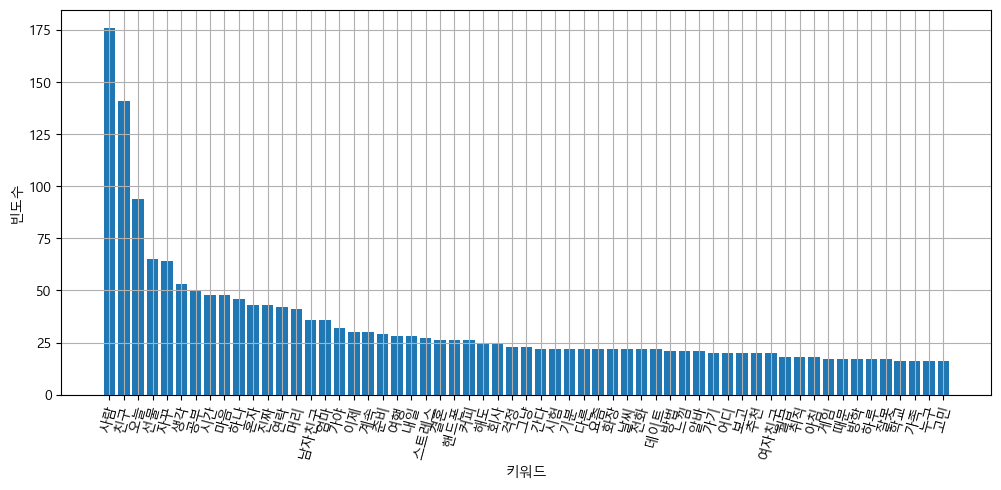

In [28]:
plt.figure(figsize = (12, 5))

sorted_Keys = sorted(word_count, key = word_count.get, reverse = True)
sorted_Values = sorted(word_count.values(), reverse = True)

plt.bar(range(len(word_count)), sorted_Values, align = 'center')

plt.xlabel('키워드')
plt.ylabel('빈도수')
plt.grid(True)
plt.xticks(range(len(word_count)), list(sorted_Keys), rotation = 75)
plt.show()

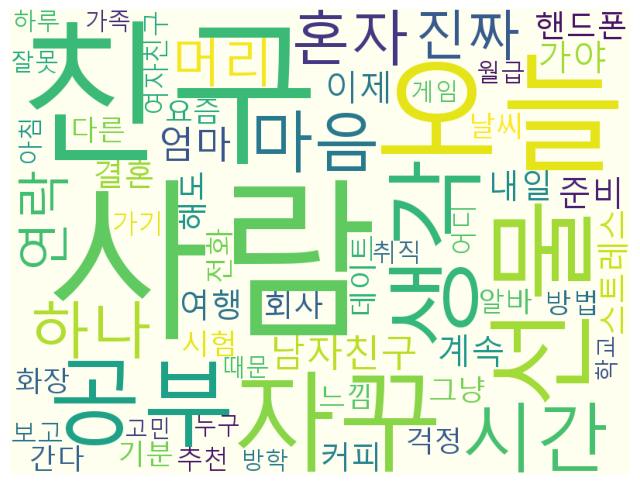

In [29]:
wc = WordCloud( font_path, background_color = 'ivory', width = 800, height = 600)

cloud = wc.generate_from_frequencies(word_count)

plt.figure(figsize = (8, 8))
plt.imshow(cloud)
plt.axis('off')
plt.show()